**Business Findings and Recommendations**

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset Shape:", df.shape)
display(df.head())

Saving Superstore_clean_Data.csv to Superstore_clean_Data (3).csv
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [22]:
print("Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Missing Values:
Series([], dtype: int64)

Duplicate Rows: 0

Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [23]:
# Convert columns to correct data types
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Business overview
print("Total Sales:", round(df['Sales'].sum(), 2))
print("Total Profit:", round(df['Profit'].sum(), 2))
print("Overall Profit Margin (%):", round(df['Profit'].sum() / df['Sales'].sum() * 100, 2))

print("\nProfit by Category:")
display(df.groupby('Category')[['Sales', 'Profit']].sum().round(2))

Total Sales: 2297200.86
Total Profit: 286397.02
Overall Profit Margin (%): 12.47

Profit by Category:


,Sales,Profit
Category,,
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80
Technology,836154.03,145454.95


In [24]:
# Profit analysis by discount level
df['Discount Band'] = pd.cut(
    df['Discount'],
    bins=[-0.01, 0, 0.20, 0.40, 1],
    labels=['0%', '1-20%', '21-40%', 'Over 40%']
)

discount_analysis = df.groupby('Discount Band', observed=False).agg(
    Orders=('Order ID', 'count'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum')
)

discount_analysis['Profit Margin (%)'] = (
    discount_analysis['Profit'] / discount_analysis['Sales'] * 100
).round(2)

display(discount_analysis.round(2))

,Orders,Sales,Profit,Profit Margin (%)
Discount Band,,,,
0%,4798,1087908.47,320987.60,29.51
1-20%,3803,846522.24,100785.47,11.91
21-40%,460,234137.90,-35817.47,-15.30
Over 40%,933,128632.25,-99558.59,-77.40


In [25]:
# 1. Profit by Sub-Category
subcat_profit = df.groupby('Sub-Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).sort_values('Total_Profit')

print("Lowest Profit Sub-Categories:")
display(subcat_profit.head(10).round(2))

# 2. Five products with the biggest losses
product_losses = df.groupby('Product Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).sort_values('Total_Profit')

print("Five Products with the Biggest Losses:")
display(product_losses.head(5).round(2))

Lowest Profit Sub-Categories:


,Total_Sales,Total_Profit
Sub-Category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10
Fasteners,3024.28,949.52
Machines,189238.63,3384.76
Labels,12486.31,5546.25
Art,27118.79,6527.79
Envelopes,16476.40,6964.18
Furnishings,91705.16,13059.14


Five Products with the Biggest Losses:


,Total_Sales,Total_Profit
Product Name,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40


In [26]:
# Profit analysis by Region
print("Profit by Region:")
region_analysis = df.groupby('Region').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum')
)
region_analysis['Profit Margin (%)'] = (
    region_analysis['Profit'] / region_analysis['Sales'] * 100
)
display(region_analysis.round(2))

# Profit analysis by Customer Segment
print("Profit by Customer Segment:")
segment_analysis = df.groupby('Segment').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum')
)
segment_analysis['Profit Margin (%)'] = (
    segment_analysis['Profit'] / segment_analysis['Sales'] * 100
)
display(segment_analysis.round(2))

Profit by Region:


,Sales,Profit,Profit Margin (%)
Region,,,
Central,501239.89,39706.36,7.92
East,678781.24,91522.78,13.48
South,391721.90,46749.43,11.93
West,725457.82,108418.45,14.94


Profit by Customer Segment:


,Sales,Profit,Profit Margin (%)
Segment,,,
Consumer,1161401.34,134119.21,11.55
Corporate,706146.37,91979.13,13.03
Home Office,429653.15,60298.68,14.03


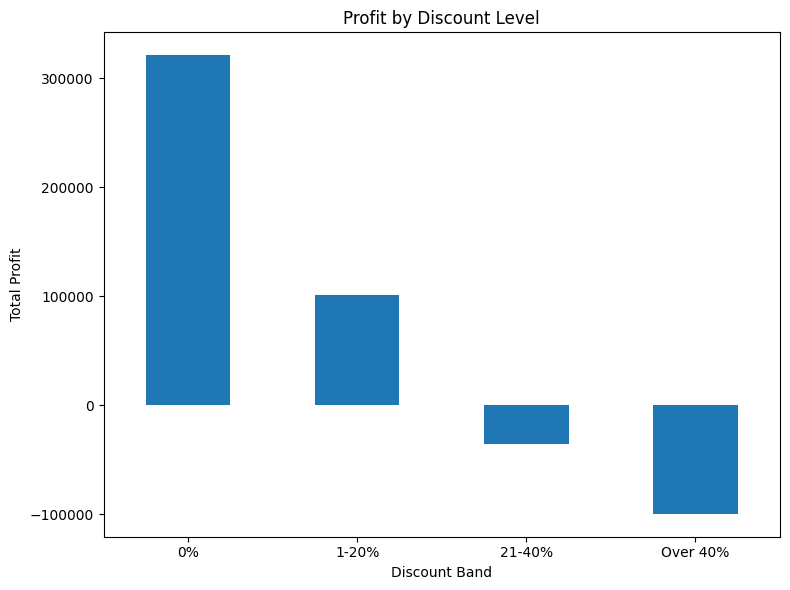

In [27]:
import matplotlib.pyplot as plt

discount_analysis['Profit'].plot(kind='bar', figsize=(8, 6))
plt.title('Profit by Discount Level')
plt.xlabel('Discount Band')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

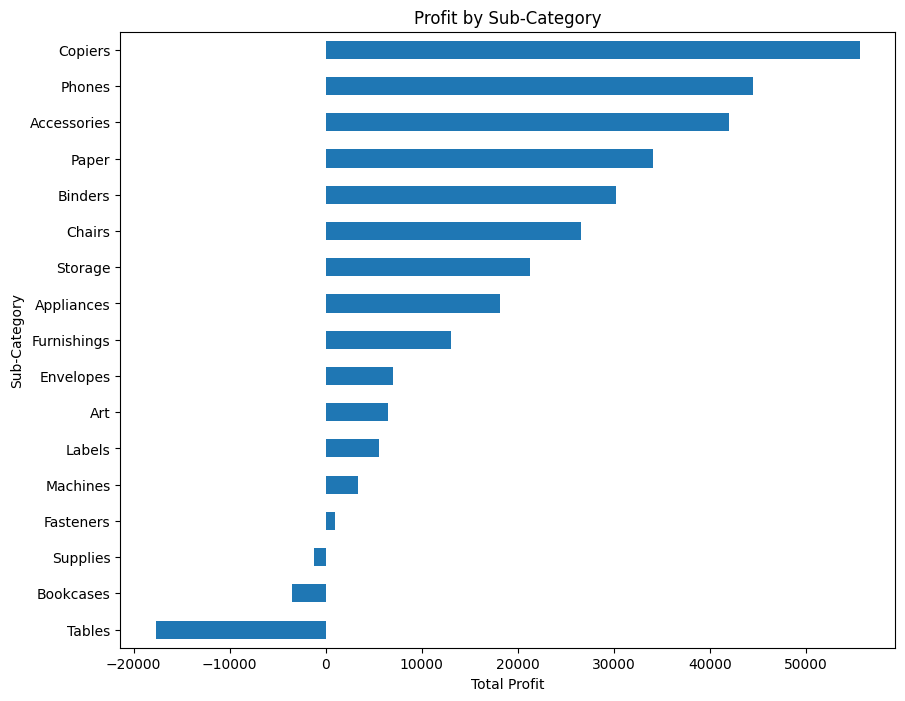

In [28]:
# Chart 1: Sub-Category profit
plt.figure(figsize=(10, 8))
df.groupby('Sub-Category')['Profit'].sum().sort_values().plot(kind='barh')
plt.title('Profit by Sub-Category')
plt.xlabel('Total Profit')
plt.show()



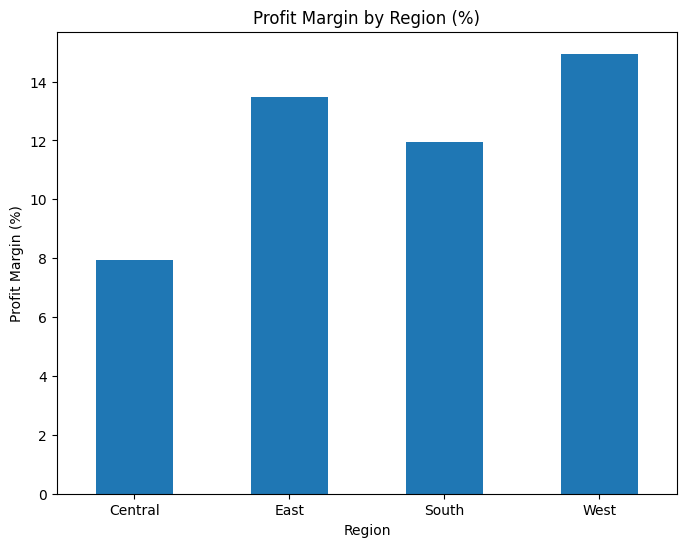

In [29]:
# Chart 2: Region margin
plt.figure(figsize=(8, 6))
region_analysis['Profit Margin (%)'].plot(kind='bar')
plt.title('Profit Margin by Region (%)')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.show()

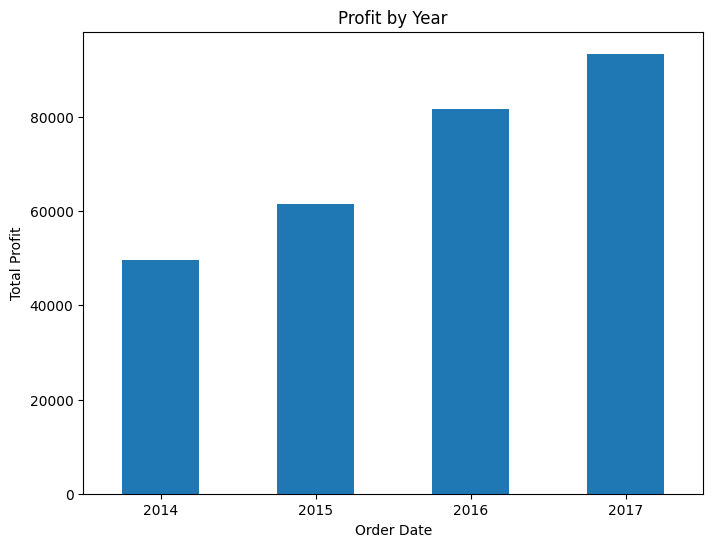

In [30]:
# Chart 3: Yearly profit
plt.figure(figsize=(8, 6))
df.groupby(df['Order Date'].dt.year)['Profit'].sum().plot(kind='bar')
plt.title('Profit by Year')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.show()